# Portuguese Bank Marketing: Term Deposit Subscription Analysis

**Prepared by:** DEENA JOSE  
**Date:** 14 November 2026  
**Project:** PRCP-1000 Portuguese Bank Marketing  
**Domain:** Finance / Banking

---

## Executive Summary

| | |
|---|---|
| **Business goal** | Help the bank's telemarketing team decide *which customers to call* to sell term deposits, so that fewer calls produce more subscriptions. |
| **Data** | 41,176 customers contacted between May 2008 and November 2010 (`bank-additional-full.csv`), after removing 12 exact duplicates. Only 11.3% subscribed, so the target is strongly imbalanced. |
| **Key modelling decision** | `duration` (call length) is **excluded** from the production model because it is only known after the call ends. It is used only in a benchmark to show how much it would inflate results. |
| **Recommended model** | **Random Forest (tuned)**: average precision 0.486, ROC-AUC 0.814, recall on subscribers 0.64 on a held-out test set (the top four models are statistically tied, see 7.2). |
| **Business impact** | Calling only the top-scored 20% of customers reaches about **66%** of all subscribers (lift 3.3x versus calling at random). |
| **Top actions** | (1) Re-contact previous-campaign successes first. (2) Call mobile (cellular) numbers rather than landlines. (3) Prioritise students and retirees. (4) Use the model score to rank the call list. (5) Cap repeated attempts per customer. |

## Notebook Contents

1. Introduction and Business Problem
2. Data Loading
3. Data Overview and Data Quality
4. Exploratory Data Analysis (Task 1)
5. Feature Preparation
6. Predictive Modelling (Task 2)
7. Model Comparison and Production Recommendation
8. Marketing Recommendations (Task 3)
9. Challenges and Solutions
10. Conclusion, Limitations and Next Steps

## 1. Introduction and Business Problem

A Portuguese bank ran direct phone-call marketing campaigns to sell **term deposits** to existing customers between May 2008 and November 2010. Each call costs agent time, and most calls end in a refusal. The marketing team therefore needs to answer two questions:

1. **Who is most likely to subscribe?** (a predictive model)
2. **What should we do differently to convert more customers?** (data-driven recommendations)

### Project objectives (from the brief)

| Task | Deliverable | Where in this notebook |
|---|---|---|
| Task 1 | Complete data analysis report | Sections 3 and 4 |
| Task 2 | Predictive model for who will subscribe | Sections 5 and 6 |
| Task 3 | Suggestions to the marketing team | Section 8 |
| Extra | Model comparison report | Section 7 |
| Extra | Report on challenges faced | Section 9 |

### How success is measured

Only about 1 in 9 customers subscribes, so a model that predicts "no" for everyone would be about 89% accurate and completely useless. Instead the notebook uses **average precision (area under the precision-recall curve)** as the main ranking metric, together with ROC-AUC, and precision / recall / F1 for the subscriber class.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")          # keep the notebook output readable
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42

## 2. Data Loading

The brief specifies `bank-additional-full.csv`. The file is **semicolon-separated**, so `sep=";"` is required. The loader below looks for the file in a few relative locations so the notebook runs on any machine (place the CSV in a `data/` folder next to the notebook).

In [2]:
csv_path = r"D:\Portuguese_Bank_Marketing\data\bank-additional-full.csv"
df = pd.read_csv(csv_path, sep=";")
print("Loaded:", csv_path)
print("Dataset shape:", df.shape)
display(df.head())
df.info()



Loaded: D:\Portuguese_Bank_Marketing\data\bank-additional-full.csv
Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.100,93.994,-36.400,4.857,"5,191.000",no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

## 3. Data Overview and Data Quality

This section checks column types, duplicates, missing values, the special value `unknown`, and the balance of the target.

In [3]:
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
print("Missing (NaN) values in total:", int(df.isna().sum().sum()))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [4]:
# "unknown" is stored as a category, not as a blank cell, so it must be counted separately
cat_cols_all = df.select_dtypes(include="object").columns.drop("y")
unknown_counts = df[cat_cols_all].eq("unknown").sum()
unknown_summary = pd.DataFrame({
    "unknown values": unknown_counts,
    "% of rows": unknown_counts / len(df) * 100,
})
display(unknown_summary[unknown_summary["unknown values"] > 0].sort_values("unknown values", ascending=False))

# Target balance
target_summary = pd.DataFrame({
    "count": df["y"].value_counts(),
    "percentage": df["y"].value_counts(normalize=True) * 100,
})
display(target_summary)

,unknown values,% of rows
default,8597,20.873
education,1731,4.203
housing,990,2.404
loan,990,2.404
job,330,0.801
marital,80,0.194


,count,percentage
y,,
no,36548,88.735
yes,4640,11.265


In [5]:
# Remove exact duplicate rows. Row order is preserved (the file is roughly chronological,
# which is used later for a time-aware validation check).
df_clean = df.drop_duplicates().reset_index(drop=True)
overall_rate = (df_clean["y"] == "yes").mean() * 100

print("Original rows:", len(df))
print("Rows after removing exact duplicates:", len(df_clean))
print(f"Subscription rate after cleaning: {overall_rate:.2f}%")

Original rows: 41188
Rows after removing exact duplicates: 41176
Subscription rate after cleaning: 11.27%


**Data quality findings**

- There are **no blank (NaN) cells**, but six categorical columns use the label `unknown` (largest: `default` with 8,597 rows, 21% of the data). `unknown` is kept as its own category because *not knowing* a customer's credit-default status may itself carry information (checked in the EDA).
- **12 exact duplicate rows** were removed from the working copy (`df_clean`); the original `df` is kept untouched.
- The target is **imbalanced**: about 11.3% "yes" versus 88.7% "no". Accuracy alone would be misleading.

## 4. Exploratory Data Analysis (Task 1)

The EDA covers: numeric summaries, distributions and outliers, the effect of call duration, subscription rates for every categorical variable, customer age, contact history, the economic indicators and their collinearity, and a short summary of insights.

### 4.1 Numeric summary and target distribution

,count,mean,std,min,25%,50%,75%,max
age,"41,176.000",40.024,10.421,17.000,32.000,38.000,47.000,98.000
duration,"41,176.000",258.316,259.305,0.000,102.000,180.000,319.000,"4,918.000"
campaign,"41,176.000",2.568,2.770,1.000,1.000,2.000,3.000,56.000
pdays,"41,176.000",962.465,186.937,0.000,999.000,999.000,999.000,999.000
previous,"41,176.000",0.173,0.495,0.000,0.000,0.000,0.000,7.000
emp.var.rate,"41,176.000",0.082,1.571,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,"41,176.000",93.576,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,"41,176.000",-40.503,4.628,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,"41,176.000",3.621,1.734,0.634,1.344,4.857,4.961,5.045
nr.employed,"41,176.000","5,167.035",72.251,"4,963.600","5,099.100","5,191.000","5,228.100","5,228.100"


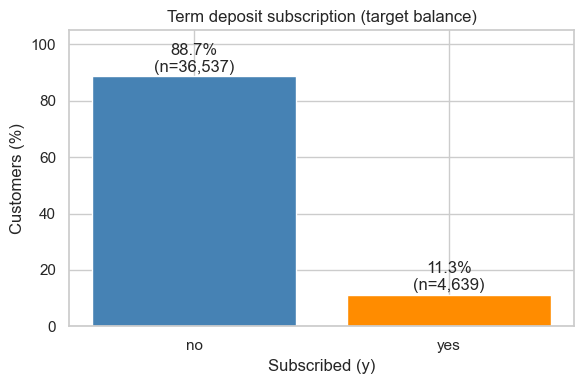

In [6]:
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()
display(df_clean[numeric_cols].describe().T)

counts = df_clean["y"].value_counts().reindex(["no", "yes"])
pct = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, pct.values, color=["steelblue", "darkorange"])
for b, p, c in zip(bars, pct.values, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, p + 1.5, f"{p:.1f}%\n(n={c:,})", ha="center")
ax.set_ylim(0, 105); ax.set_ylabel("Customers (%)"); ax.set_xlabel("Subscribed (y)")
ax.set_title("Term deposit subscription (target balance)")
plt.tight_layout(); plt.show()

**Insight:** only about 1 customer in 9 subscribes. This is the central modelling challenge, and it is why stratified sampling, class weights and precision-recall metrics are used later. `pdays` has a median of 999 and `previous` is almost always 0: most customers were never contacted before this campaign.

### 4.2 Distributions and outliers

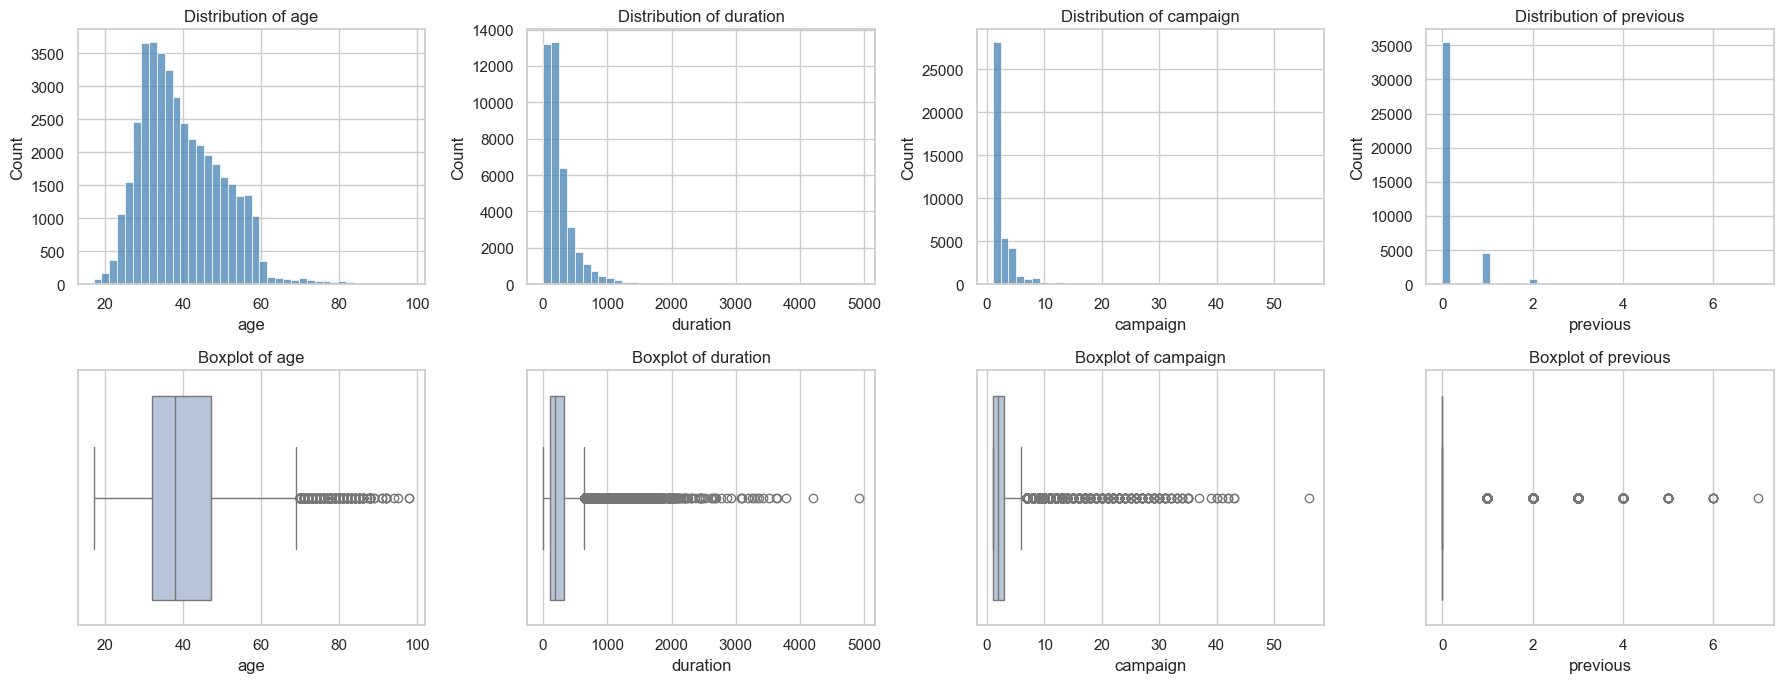

,upper fence,outliers,% of rows,max
feature,,,,
age,69.500,468,1.137,98
duration,644.500,2963,7.196,4918
campaign,6.000,2406,5.843,56
previous,0.000,5625,13.661,7


In [7]:
dist_cols = ["age", "duration", "campaign", "previous"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(dist_cols):
    sns.histplot(df_clean[col], bins=40, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(x=df_clean[col], ax=axes[1, i], color="lightsteelblue")
    axes[1, i].set_title(f"Boxplot of {col}")
plt.tight_layout(); plt.show()

# IQR-rule outlier counts
rows = []
for col in dist_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    n_out = int((df_clean[col] > upper).sum())
    rows.append({"feature": col, "upper fence": upper, "outliers": n_out,
                 "% of rows": n_out / len(df_clean) * 100, "max": df_clean[col].max()})
display(pd.DataFrame(rows).set_index("feature"))

**Insight:** `age`, `duration`, `campaign` and `previous` are all right-skewed with long upper tails (for example some customers were called more than 40 times in one campaign). These extreme values are genuine records rather than data-entry errors, and tree-based models are not sensitive to them, so they are **kept**. Where a linear model is used, standard scaling is applied inside the pipeline.

### 4.3 Call duration versus the outcome (why it must be excluded)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,"36,537.000",220.868,207.116,0.000,95.000,164.000,279.000,"4,918.000"
yes,"4,639.000",553.256,401.191,37.000,253.500,449.000,741.500,"4,199.000"


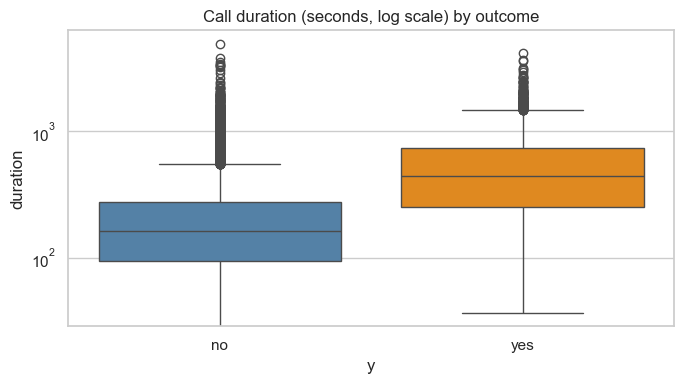

In [8]:
display(df_clean.groupby("y")["duration"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df_clean, x="y", y="duration", order=["no", "yes"],
            palette=["steelblue", "darkorange"], ax=ax)
ax.set_yscale("log"); ax.set_title("Call duration (seconds, log scale) by outcome")
plt.tight_layout(); plt.show()

**Insight:** subscribers talked far longer: the median call lasts 449 s for "yes" versus 164 s for "no". But call length is only known **after** the call, when the outcome is already decided. Using it to decide who to call would be circular (target leakage), so the production model excludes it. It is retained only in a benchmark in Section 6.

### 4.4 Subscription rate by customer profile

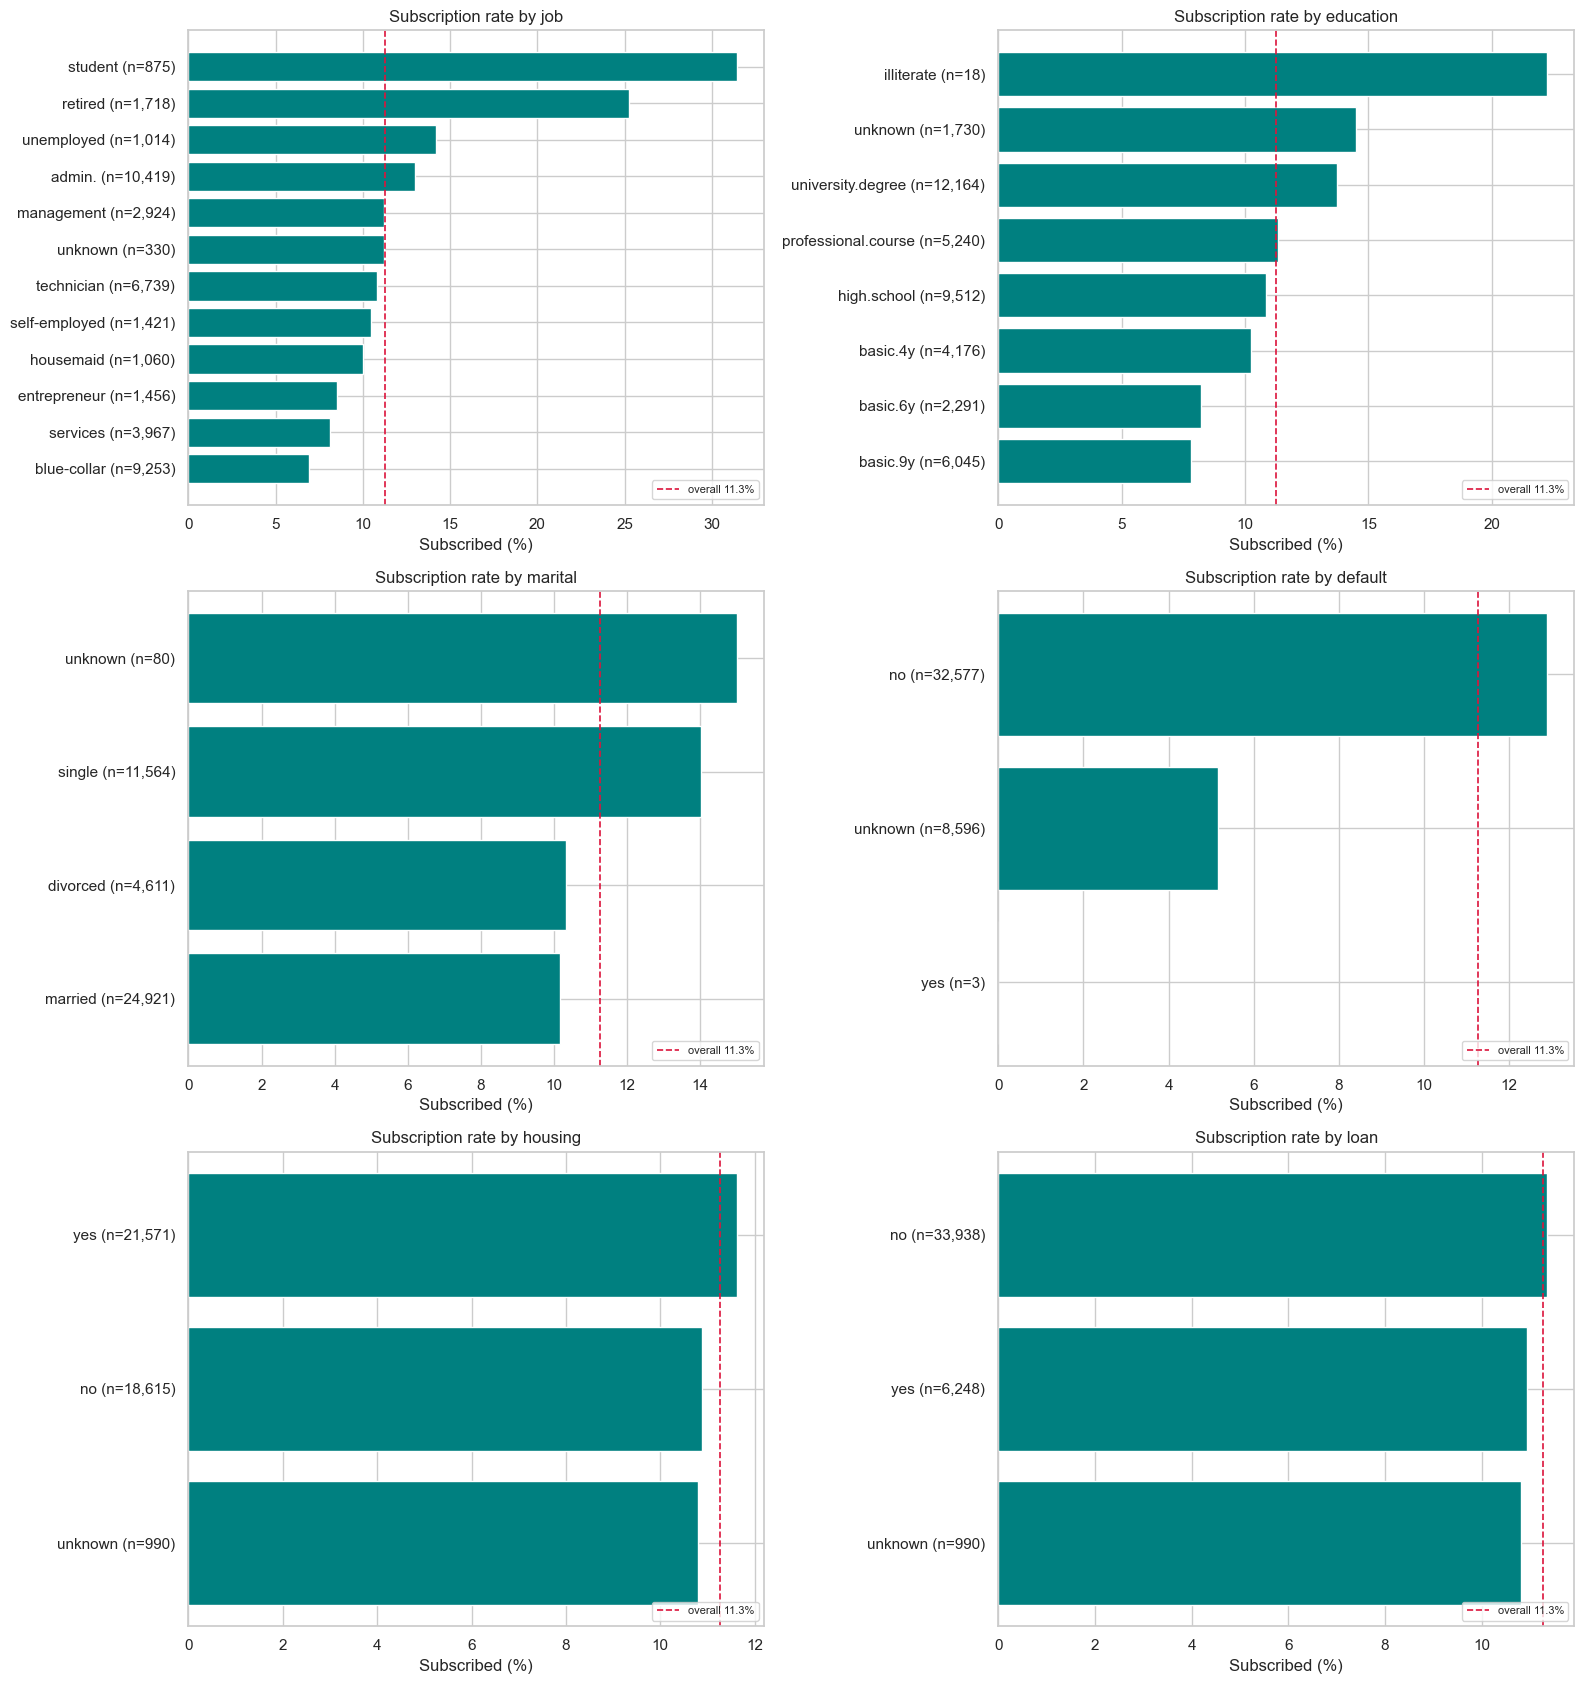

In [9]:
def seg_rate(col, value, data=None):
    """Subscription rate (%) for one category value."""
    data = df_clean if data is None else data
    return (data.loc[data[col] == value, "y"] == "yes").mean() * 100

def seg_n(col, value, data=None):
    data = df_clean if data is None else data
    return int((data[col] == value).sum())

def plot_rates(cols, ncols, figsize, orders=None, data=None):
    """Bar charts of subscription rate per category; y-labels show group size (n)."""
    data = df_clean if data is None else data
    overall = (data["y"] == "yes").mean() * 100
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    flat = np.ravel(axes)
    for ax, col in zip(flat, cols):
        g = data.groupby(col)["y"].agg(n="size", rate=lambda s: (s == "yes").mean() * 100)
        if orders and col in orders:
            g = g.reindex([o for o in orders[col] if o in g.index])
        else:
            g = g.sort_values("rate")
        ax.barh([f"{i} (n={n:,})" for i, n in zip(g.index, g["n"])], g["rate"], color="teal")
        if orders and col in orders:
            ax.invert_yaxis()
        ax.axvline(overall, color="crimson", ls="--", lw=1.2, label=f"overall {overall:.1f}%")
        ax.set_title(f"Subscription rate by {col}"); ax.set_xlabel("Subscribed (%)")
        ax.legend(fontsize=8, loc="lower right")
    for ax in flat[len(cols):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

# Customer profile: job, education, marital status, credit variables
plot_rates(["job", "education", "marital", "default", "housing", "loan"], ncols=2, figsize=(16, 17))

**Insight (customer profile):** **students** (31.4%) and **retired** customers (25.3%) subscribe at roughly 2-3x the overall rate, while blue-collar workers and services staff are below it. Higher education (university degree: 13.7%) is associated with higher take-up. Credit-default status is striking: customers whose `default` is **`unknown`** subscribe at only 5.2% versus 12.9% for `no` (and only 3 customers have `default = yes`, none of whom subscribed). Housing and personal-loan status make little difference (all within about one percentage point of each other). Customers with an `unknown` education are above average (14.5%), so `unknown` is informative and is kept as a category.

### 4.5 Subscription rate by campaign context

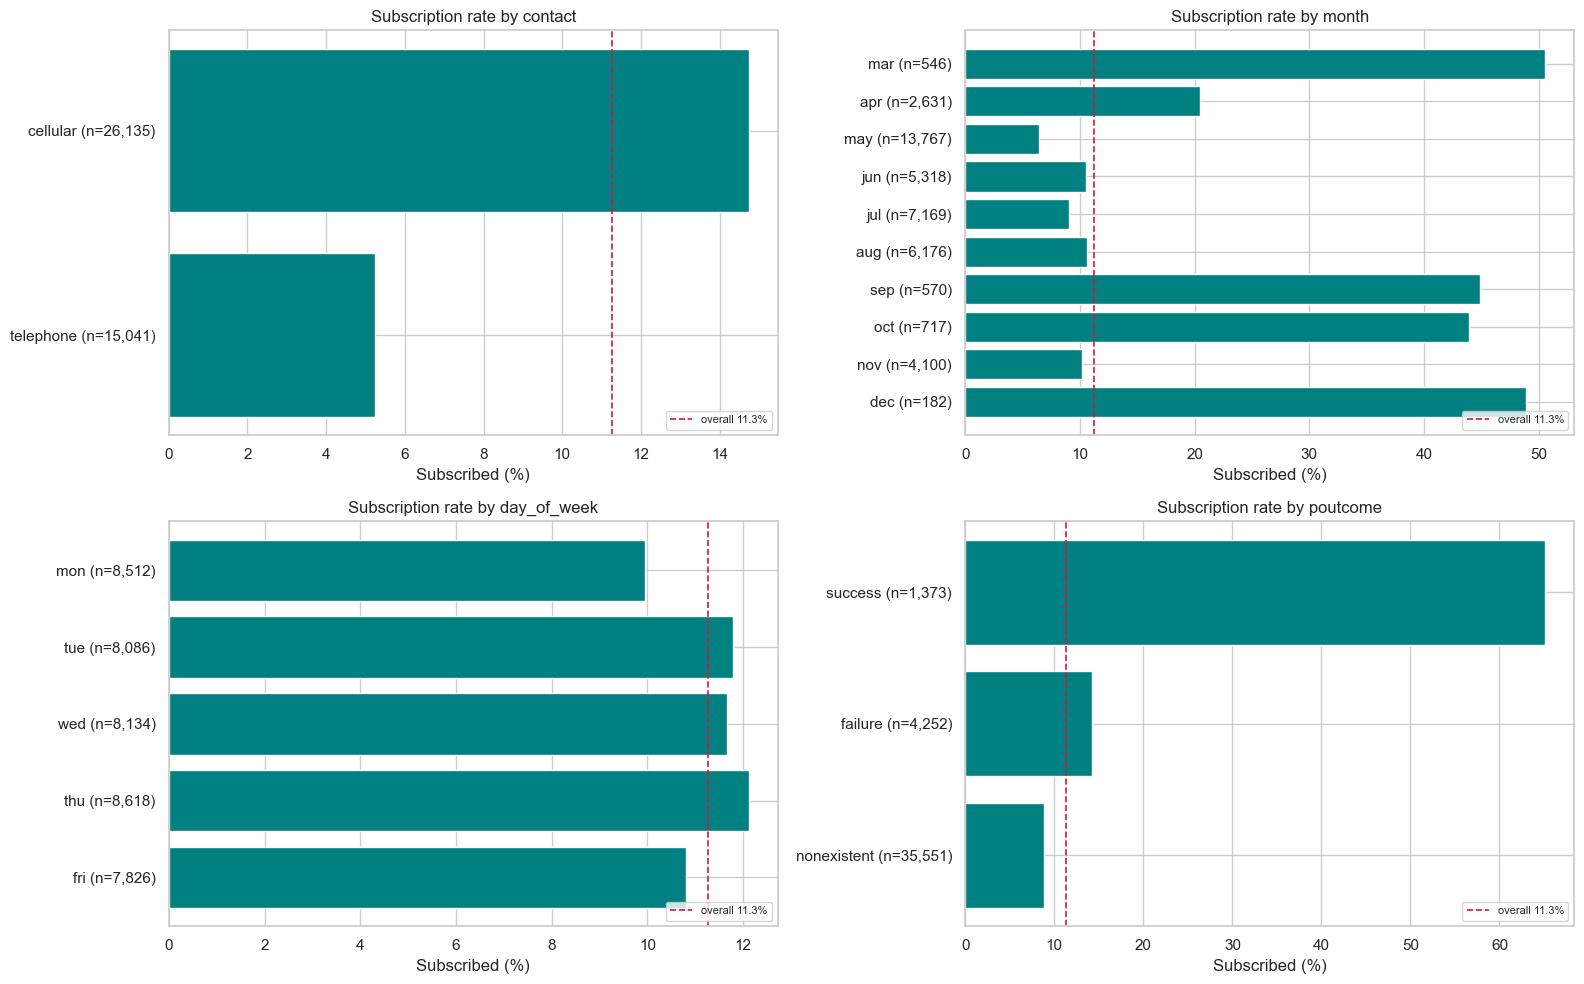

In [10]:
month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
day_order = ["mon", "tue", "wed", "thu", "fri"]
plot_rates(["contact", "month", "day_of_week", "poutcome"], ncols=2, figsize=(16, 10),
           orders={"month": month_order, "day_of_week": day_order})

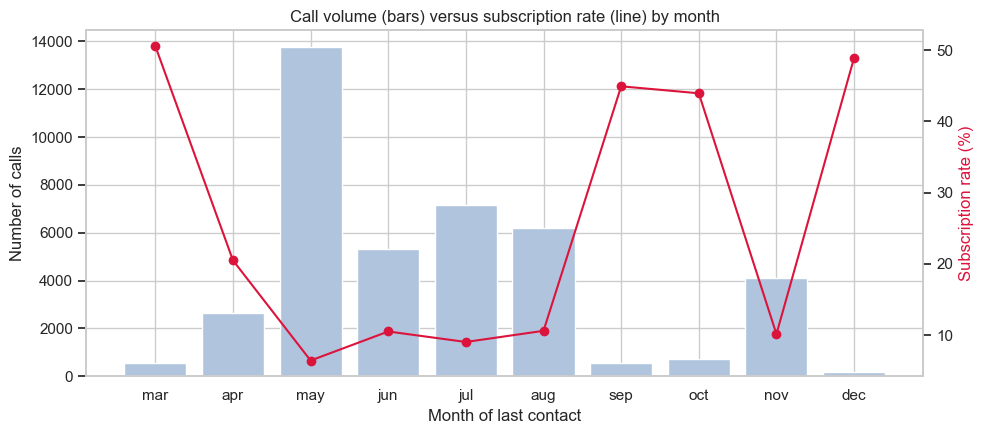

,calls,rate
month,,
mar,546,50.549
apr,2631,20.487
may,13767,6.436
jun,5318,10.511
jul,7169,9.039
aug,6176,10.606
sep,570,44.912
oct,717,43.933
nov,4100,10.146


In [11]:
# Month: call volume vs. subscription rate (the campaign is heavily concentrated in May-Aug)
m = (df_clean.groupby("month")["y"]
     .agg(calls="size", rate=lambda s: (s == "yes").mean() * 100)
     .reindex(month_order))

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(m.index, m["calls"], color="lightsteelblue")
ax1.set_ylabel("Number of calls"); ax1.set_xlabel("Month of last contact")
ax2 = ax1.twinx()
ax2.plot(m.index, m["rate"], color="crimson", marker="o")
ax2.set_ylabel("Subscription rate (%)", color="crimson"); ax2.grid(False)
ax1.set_title("Call volume (bars) versus subscription rate (line) by month")
plt.tight_layout(); plt.show()
display(m)

**Insight (campaign context):**

- **Contact channel:** cellular calls convert at 14.7% versus only 5.2% for landlines, almost 3x higher.
- **Previous outcome:** customers who subscribed in an earlier campaign (`poutcome = success`) subscribe again **65.1%** of the time, versus 8.8% for customers never contacted before. This is the strongest single segment, but it is small (n = 1,373).
- **Month:** the bank placed 33% of its calls in **May**, the month with one of the *lowest* rates (6.4%). March, September, October and December convert at roughly 44-51% (50.5%, 44.9%, 43.9%, 48.9%) but received very few calls (December only 182). Small groups make these rates noisy, but the gap is large enough to merit a test. Part of the explanation may be *who* was called in those months, not the month itself.
- **Day of week:** differences are small (about 2 percentage points between the best and worst day); weekday timing is a minor lever.

### 4.6 Age, contact history and call frequency

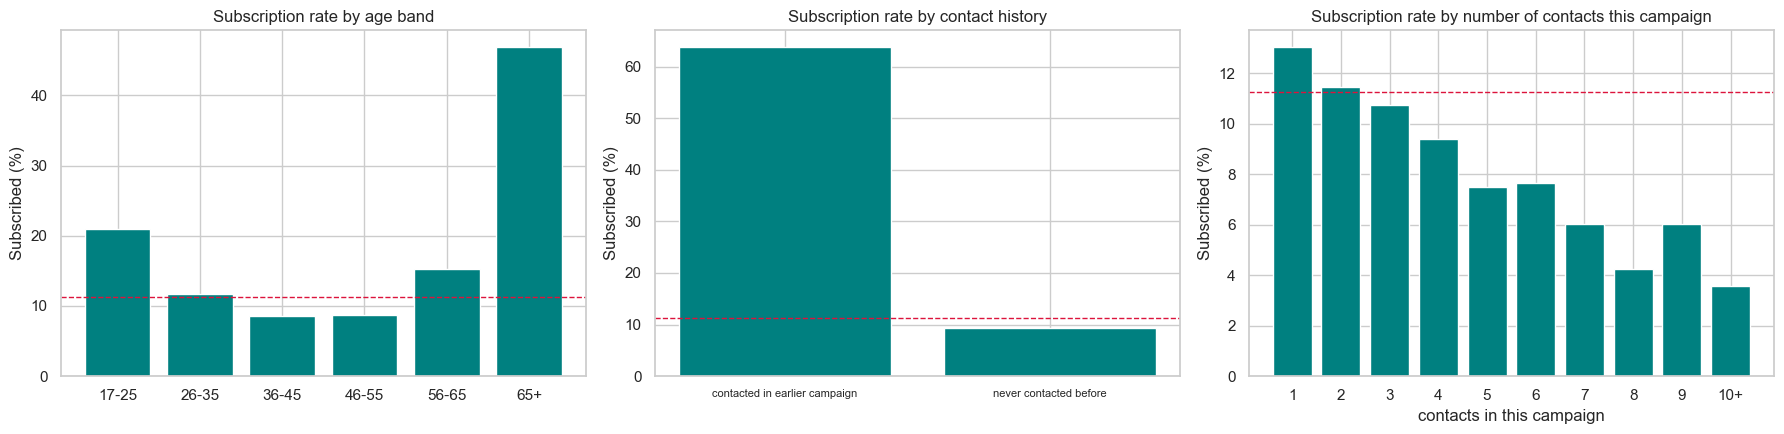

age,17-25,26-35,36-45,46-55,56-65,65+
n,"1,665.000","14,844.000","12,839.000","8,247.000","2,963.000",618.000
rate,20.961,11.722,8.505,8.694,15.221,46.926


,contacted in earlier campaign,never contacted before
n,"1,515.000","39,661.000"
rate,63.828,9.258


campaign,1,2,3,4,5,6,7,8,9,10+
n,"17,634.000","10,568.000","5,340.000","2,650.000","1,599.000",979.000,629.000,400.000,283.000,"1,094.000"
rate,13.037,11.459,10.749,9.396,7.505,7.661,6.041,4.250,6.007,3.565


In [12]:
age_bins = [16, 25, 35, 45, 55, 65, 100]
age_labels = ["17-25", "26-35", "36-45", "46-55", "56-65", "65+"]
age_band = pd.cut(df_clean["age"], bins=age_bins, labels=age_labels)
age_tbl = df_clean.groupby(age_band, observed=True)["y"].agg(n="size", rate=lambda s: (s == "yes").mean() * 100)

contact_hist = np.where(df_clean["pdays"] == 999, "never contacted before", "contacted in earlier campaign")
hist_tbl = df_clean.groupby(contact_hist)["y"].agg(n="size", rate=lambda s: (s == "yes").mean() * 100)

freq = np.minimum(df_clean["campaign"], 10).map(lambda v: "10+" if v == 10 else str(v))
freq_order = [str(i) for i in range(1, 10)] + ["10+"]
freq_tbl = df_clean.groupby(freq)["y"].agg(n="size", rate=lambda s: (s == "yes").mean() * 100).reindex(freq_order)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].bar(age_tbl.index.astype(str), age_tbl["rate"], color="teal")
axes[0].set_title("Subscription rate by age band")
axes[1].bar(hist_tbl.index, hist_tbl["rate"], color="teal"); axes[1].set_title("Subscription rate by contact history")
axes[1].tick_params(axis="x", labelsize=8)
axes[2].bar(freq_tbl.index, freq_tbl["rate"], color="teal")
axes[2].set_title("Subscription rate by number of contacts this campaign")
axes[2].set_xlabel("contacts in this campaign")
for ax in axes:
    ax.set_ylabel("Subscribed (%)")
    ax.axhline(overall_rate, color="crimson", ls="--", lw=1)
plt.tight_layout(); plt.show()

display(age_tbl.T); display(hist_tbl.T); display(freq_tbl.T)

**Insight:** subscription follows a **U-shape across age**: customers aged 17-25 (21.0%) and over 65 (46.9%) subscribe far more than the 36-55 core (about 9%). Customers contacted in an earlier campaign convert at 63.8% versus 9.3%. Call frequency shows **diminishing returns**: the rate falls from 13.0% on the first contact to 7.5% by the 5th, and 3.6% beyond 10, so repeatedly calling the same reluctant customer wastes effort. *Caveat:* this is partly a survivorship effect, because customers who say yes stop being called, so those still being called at high attempt counts are by construction the ones who kept refusing. The direction is still a useful warning against open-ended re-dialling.

### 4.7 Economic indicators and multicollinearity

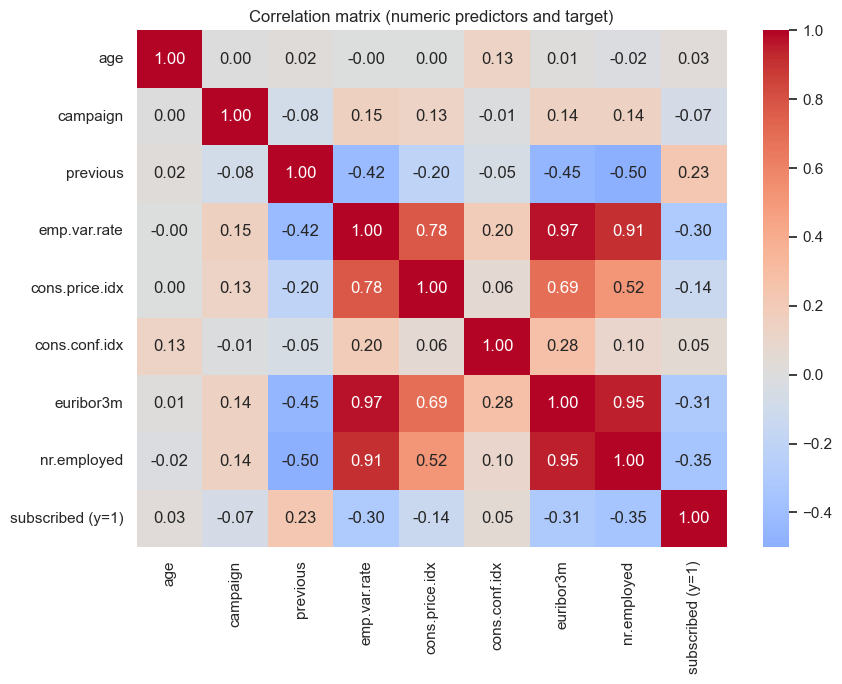

,VIF
euribor3m,64.324
emp.var.rate,33.063
nr.employed,31.621
cons.price.idx,6.314
cons.conf.idx,2.617
previous,1.349
campaign,1.034
age,1.019


,n,rate
euribor3m,,
"(0.633, 1.299]",8634,29.650
"(1.299, 4.191]",8427,10.787
"(4.191, 4.864]",8445,3.623
"(4.864, 4.962]",8496,5.520
"(4.962, 5.045]",7174,5.506


In [13]:
econ_cols = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
corr_cols = ["age", "campaign", "previous"] + econ_cols
corr_df = df_clean[corr_cols].copy()
corr_df["subscribed (y=1)"] = (df_clean["y"] == "yes").astype(int)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (numeric predictors and target)")
plt.tight_layout(); plt.show()

def vif_table(frame):
    """Variance inflation factor via least squares on standardised columns."""
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for col in X.columns:
        target = X[col].values
        others = np.column_stack([np.ones(len(X)), X.drop(columns=col).values])
        beta, *_ = np.linalg.lstsq(others, target, rcond=None)
        r2 = 1 - (target - others @ beta).var() / target.var()
        out[col] = 1 / (1 - r2)
    return pd.Series(out, name="VIF").sort_values(ascending=False).to_frame()

vif = vif_table(df_clean[corr_cols])
display(vif)

# Subscription rate across euribor3m quintiles
euribor_q = pd.qcut(df_clean["euribor3m"], 5)
eur_tbl = df_clean.groupby(euribor_q, observed=True)["y"].agg(n="size", rate=lambda s: (s == "yes").mean() * 100)
display(eur_tbl)

**Insight:** the three macro indicators `emp.var.rate`, `euribor3m` and `nr.employed` are almost perfectly correlated (e.g. correlation of `euribor3m` with `nr.employed` = 0.95; VIF up to 64, far above the usual warning level of 5-10). They are essentially the same signal (the 2008-2010 financial crisis cycle). They are also among the strongest predictors: subscription is much higher when the 3-month euribor is **low** (lowest quintile 29.7% versus highest quintile 5.5%), which fits the intuition that term deposits are attractive when interest rates and economic confidence are depressed. Section 5 explains how this collinearity is handled.

### 4.8 Summary of EDA findings

| Theme | Finding |
|---|---|
| Target | 11.3% subscribe, so the data is imbalanced |
| Leakage | `duration` is highly predictive but only known after the call, so it is excluded from production |
| Channel | Cellular 14.7% vs landline 5.2% |
| History | Previous success 65.1% vs overall 11.3% |
| Customer | Students 31%, retired 25%; U-shaped by age |
| Timing | Heavy May volume at a low rate; Mar / Sep / Oct / Dec convert far better on small volumes |
| Effort | Rates fall steadily as the number of contacts in one campaign rises |
| Macro | Low euribor / low employment variation goes with higher subscription; these indicators are highly collinear |

## 5. Feature Preparation

Decisions made before modelling, each with its reason:

| Issue | Decision | Reason |
|---|---|---|
| `pdays = 999` means "never contacted" | Add flag `previously_contacted` and set `pdays` to missing for those rows (median-imputed later *inside* the pipeline) | Treating 999 as a real number of days would distort scaling and linear models |
| `duration` known only after the call | Drop for production; keep for a clearly labelled benchmark | Prevents target leakage |
| `unknown` categories | Keep as a category | They carry signal and removing them would discard up to ~20% of rows |
| Categorical variables | One-hot encoding with `handle_unknown="ignore"` | Works for linear and tree models |
| Numeric scales differ | Standard scaling inside the pipeline | Needed for logistic regression |
| Class imbalance | Stratified split plus `class_weight="balanced"` | Preserves the 11% base rate in train and test and stops models ignoring the minority class |
| Collinear macro features | Keep all five, rely on regularised / tree models, and test the effect of dropping two | Trees tolerate collinearity; this is verified below with an ablation |

All preprocessing lives in a scikit-learn `Pipeline`, so scalers, imputers and encoders are **fitted on training data only**, which prevents leakage into the test set and into cross-validation folds.

In [14]:
from sklearn.model_selection import train_test_split

model_df = df_clean.copy()
model_df["previously_contacted"] = (model_df["pdays"] != 999).astype(int)
model_df["pdays"] = model_df["pdays"].where(model_df["pdays"] != 999, np.nan)   # imputed inside the pipeline

y = model_df["y"].map({"no": 0, "yes": 1})
X_full = model_df.drop(columns="y")              # includes duration (benchmark only)
X_prod = X_full.drop(columns="duration")         # realistic pre-call feature set

# One shared stratified split for every model
X_train_prod, X_test_prod, y_train, y_test = train_test_split(
    X_prod, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
X_train_full = X_full.loc[X_train_prod.index]
X_test_full = X_full.loc[X_test_prod.index]

print("Production features:", X_prod.shape[1], "| Benchmark features:", X_full.shape[1])
print("Train rows:", len(X_train_prod), "| Test rows:", len(X_test_prod))
print(f"Subscription rate  full: {y.mean():.4f}  train: {y_train.mean():.4f}  test: {y_test.mean():.4f}")

Production features: 20 | Benchmark features: 21
Train rows: 32940 | Test rows: 8236
Subscription rate  full: 0.1127  train: 0.1127  test: 0.1127


## 6. Predictive Modelling (Task 2)

Six model families are compared, from a simple interpretable baseline to boosted ensembles:

- **Logistic Regression**: interpretable linear baseline
- **Decision Tree**: simple non-linear model
- **Random Forest** and **Extra Trees**: bagged tree ensembles
- **AdaBoost** and **Gradient Boosting**: boosted ensembles

Each is trained twice: **without `duration` (production)** and **with `duration` (benchmark)**. Then the production models are cross-validated, the two strongest families are tuned, and the winner is analysed in depth (curves, thresholds, lift, feature importance, time-aware check).

### 6.1 Pipeline and model definitions

In [15]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

def make_preprocessor(X_part):
    num = X_part.select_dtypes(include="number").columns.tolist()
    cat = X_part.select_dtypes(include=["object", "category"]).columns.tolist()
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=5,
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=5,
                                        n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", learning_rate=0.05,
                                                        max_iter=200, random_state=RANDOM_STATE),
}

def build_pipeline(model, X_part):
    return Pipeline([("prep", make_preprocessor(X_part)), ("model", clone(model))])

def evaluate(pipe, X_te, y_te, threshold=0.5):
    """Test-set metrics. Precision / recall / F1 refer to the subscriber ('yes') class."""
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_te, pred),
            "precision_yes": precision_score(y_te, pred, zero_division=0),
            "recall_yes": recall_score(y_te, pred, zero_division=0),
            "f1_yes": f1_score(y_te, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_te, proba),
            "average_precision": average_precision_score(y_te, proba)}

### 6.2 Baseline comparison: production features versus the duration benchmark

In [16]:
rows, fitted = [], {}
setups = {"Production (no duration)": (X_train_prod, X_test_prod),
          "Benchmark (with duration)": (X_train_full, X_test_full)}

for setup, (X_tr, X_te) in setups.items():
    for name, model in models.items():
        pipe = build_pipeline(model, X_tr).fit(X_tr, y_train)
        fitted[(setup, name)] = pipe
        rows.append({"setup": setup, "model": name, **evaluate(pipe, X_te, y_test)})

baseline_df = pd.DataFrame(rows)
display(baseline_df.sort_values(["setup", "average_precision"], ascending=[True, False]).reset_index(drop=True))

,setup,model,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,average_precision
0,Benchmark (with duration),Random Forest,0.894,0.516,0.879,0.651,0.950,0.670
1,Benchmark (with duration),Gradient Boosting,0.869,0.459,0.929,0.615,0.951,0.665
2,Benchmark (with duration),Extra Trees,0.878,0.474,0.781,0.590,0.928,0.601
3,Benchmark (with duration),Logistic Regression,0.865,0.450,0.908,0.602,0.940,0.592
4,Benchmark (with duration),AdaBoost,0.905,0.652,0.328,0.436,0.936,0.588
5,Benchmark (with duration),Decision Tree,0.870,0.459,0.839,0.594,0.895,0.545
6,Production (no duration),Gradient Boosting,0.850,0.399,0.654,0.496,0.815,0.489
7,Production (no duration),Random Forest,0.872,0.451,0.611,0.519,0.805,0.483
8,Production (no duration),Extra Trees,0.849,0.393,0.628,0.484,0.799,0.474
9,Production (no duration),Logistic Regression,0.830,0.359,0.645,0.462,0.800,0.446


setup,Benchmark (with duration),Production (no duration),inflation
model,,,
Gradient Boosting,0.665,0.489,0.176
Random Forest,0.670,0.483,0.187
Extra Trees,0.601,0.474,0.126
Logistic Regression,0.592,0.446,0.146
AdaBoost,0.588,0.444,0.144
Decision Tree,0.545,0.389,0.156


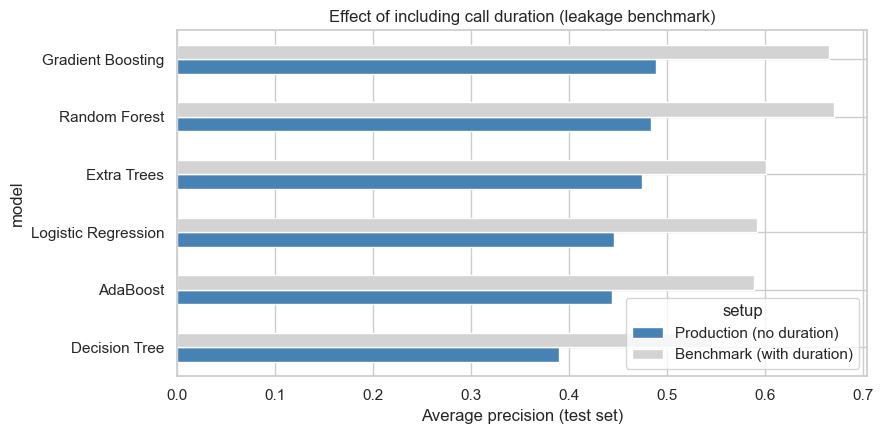

In [17]:
# How much would call duration inflate performance?
cmp = (baseline_df.pivot(index="model", columns="setup", values="average_precision")
       .assign(inflation=lambda d: d["Benchmark (with duration)"] - d["Production (no duration)"]))
display(cmp.sort_values("Production (no duration)", ascending=False))

cmp[["Production (no duration)", "Benchmark (with duration)"]].sort_values("Production (no duration)").plot(
    kind="barh", figsize=(9, 4.5), color=["steelblue", "lightgray"])
plt.xlabel("Average precision (test set)"); plt.title("Effect of including call duration (leakage benchmark)")
plt.tight_layout(); plt.show()

**Insight:** including `duration` lifts every model substantially (average precision rises by about 0.16 on average). This is the leakage effect: the benchmark numbers look impressive but could never be reproduced when deciding who to call, because call length is unknown beforehand. **Only the production (no-duration) results are used for model selection.**

### 6.3 Cross-validation of the production models (training data only)

A single train/test split can be lucky. Here every production model is scored with **5-fold stratified cross-validation** on the training set, which also gives an estimate of stability (standard deviation across folds).

In [18]:
from sklearn.model_selection import StratifiedKFold, cross_validate

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scoring = {"ap": "average_precision", "auc": "roc_auc"}

def cv_summary(name, pipe):
    res = cross_validate(pipe, X_train_prod, y_train, cv=skf, scoring=cv_scoring, n_jobs=1)
    return {"model": name,
            "cv_average_precision": res["test_ap"].mean(), "cv_ap_std": res["test_ap"].std(),
            "cv_roc_auc": res["test_auc"].mean(), "cv_auc_std": res["test_auc"].std()}

cv_rows = [cv_summary(name, build_pipeline(model, X_train_prod)) for name, model in models.items()]
cv_df = pd.DataFrame(cv_rows).set_index("model").sort_values("cv_average_precision", ascending=False)
display(cv_df)

,cv_average_precision,cv_ap_std,cv_roc_auc,cv_auc_std
model,,,,
Random Forest,0.466,0.016,0.795,0.009
Gradient Boosting,0.466,0.017,0.800,0.008
Extra Trees,0.454,0.015,0.789,0.010
Logistic Regression,0.446,0.013,0.791,0.008
AdaBoost,0.429,0.011,0.786,0.009
Decision Tree,0.356,0.009,0.738,0.004


### 6.4 Hyperparameter tuning

The two strongest production families from the cross-validation (Random Forest and Gradient Boosting) are tuned with **randomised search**, optimising average precision over stratified folds on the **training set only**. The test set is untouched until the final evaluation.

In [19]:
from sklearn.model_selection import RandomizedSearchCV

cv_tune = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rf_search = RandomizedSearchCV(
    build_pipeline(RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE), X_train_prod),
    param_distributions={"model__n_estimators": [200, 300],
                         "model__max_depth": [8, 12, 16],
                         "model__min_samples_leaf": [5, 10, 20],
                         "model__max_features": ["sqrt", 0.3]},
    n_iter=6, scoring="average_precision", cv=cv_tune, random_state=RANDOM_STATE, n_jobs=1)
rf_search.fit(X_train_prod, y_train)

gb_search = RandomizedSearchCV(
    build_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE), X_train_prod),
    param_distributions={"model__learning_rate": [0.03, 0.05, 0.1],
                         "model__max_iter": [100, 200, 300],
                         "model__max_leaf_nodes": [7, 15, 31],
                         "model__min_samples_leaf": [20, 50, 100],
                         "model__l2_regularization": [0.0, 1.0, 10.0]},
    n_iter=10, scoring="average_precision", cv=cv_tune, random_state=RANDOM_STATE, n_jobs=1)
gb_search.fit(X_train_prod, y_train)

print("Random Forest  best CV AP:", round(rf_search.best_score_, 4), rf_search.best_params_)
print("Gradient Boost best CV AP:", round(gb_search.best_score_, 4), gb_search.best_params_)

Random Forest  best CV AP: 0.4653 {'model__n_estimators': 200, 'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': 16}
Gradient Boost best CV AP: 0.4643 {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 31, 'model__max_iter': 200, 'model__learning_rate': 0.1, 'model__l2_regularization': 10.0}


### 6.5 Model selection

All production candidates (6 baselines plus 2 tuned) are compared on the same 5-fold cross-validation, and the model with the highest **cross-validated average precision** is selected. This selection uses training data only. The test set is then used once to report final performance.

In [20]:
candidates = {name: build_pipeline(m, X_train_prod) for name, m in models.items()}
candidates["Random Forest (tuned)"] = rf_search.best_estimator_
candidates["Gradient Boosting (tuned)"] = gb_search.best_estimator_

selection_rows = [cv_summary(name, clone(p)) for name, p in candidates.items()]
selection_df = pd.DataFrame(selection_rows).set_index("model").sort_values("cv_average_precision", ascending=False)
display(selection_df)

best_name = selection_df.index[0]
print("Selected production model:", best_name)

# Fit every candidate on the full training set and score on the untouched test set
final_models = {name: clone(p).fit(X_train_prod, y_train) for name, p in candidates.items()}
test_df = pd.DataFrame({name: evaluate(p, X_test_prod, y_test) for name, p in final_models.items()}).T
test_df = test_df.sort_values("average_precision", ascending=False)
display(test_df)

best_pipe = final_models[best_name]
best_row = test_df.loc[best_name]
best_proba = best_pipe.predict_proba(X_test_prod)[:, 1]

,cv_average_precision,cv_ap_std,cv_roc_auc,cv_auc_std
model,,,,
Random Forest (tuned),0.467,0.017,0.799,0.010
Gradient Boosting (tuned),0.467,0.015,0.800,0.010
Random Forest,0.466,0.016,0.795,0.009
Gradient Boosting,0.466,0.017,0.800,0.008
Extra Trees,0.454,0.015,0.789,0.010
Logistic Regression,0.446,0.013,0.791,0.008
AdaBoost,0.429,0.011,0.786,0.009
Decision Tree,0.356,0.009,0.738,0.004


Selected production model: Random Forest (tuned)


,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,average_precision
Random Forest (tuned),0.865,0.433,0.634,0.514,0.812,0.489
Gradient Boosting,0.850,0.399,0.654,0.496,0.815,0.489
Gradient Boosting (tuned),0.845,0.390,0.658,0.490,0.813,0.489
Random Forest,0.872,0.451,0.611,0.519,0.805,0.483
Extra Trees,0.849,0.393,0.628,0.484,0.799,0.474
Logistic Regression,0.830,0.359,0.645,0.462,0.800,0.446
AdaBoost,0.899,0.690,0.182,0.288,0.796,0.444
Decision Tree,0.746,0.255,0.651,0.366,0.753,0.389


### 6.6 ROC and precision-recall curves

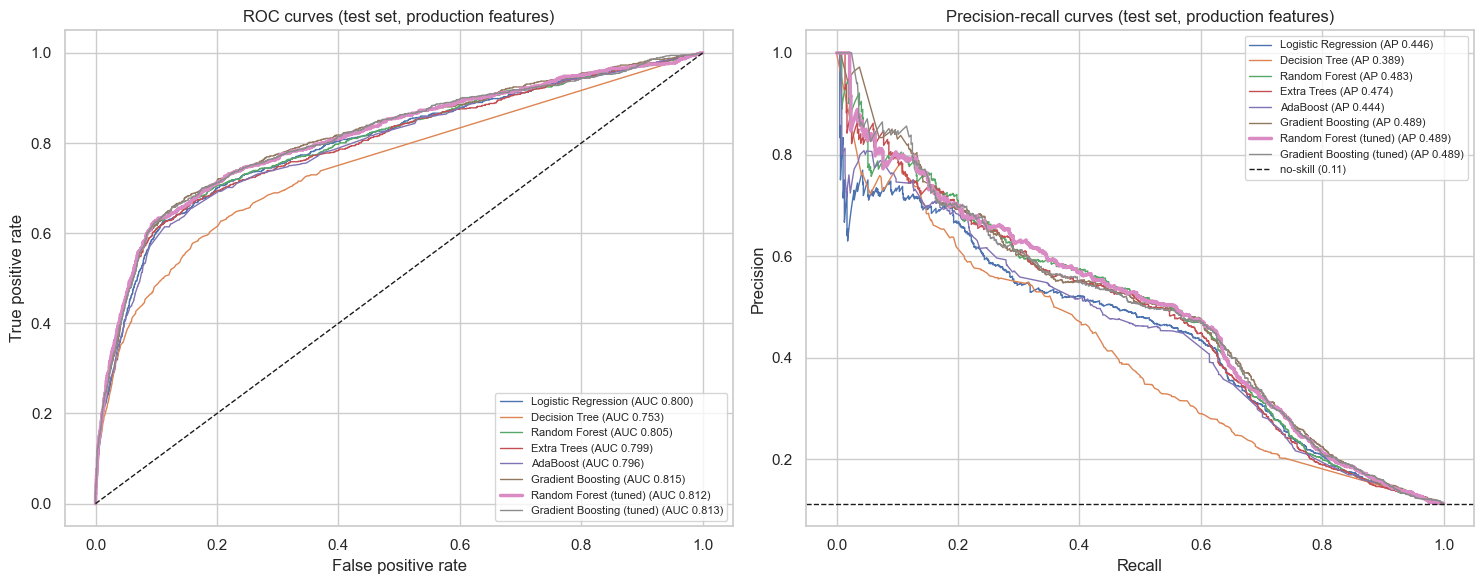

In [21]:
from sklearn.metrics import roc_curve, precision_recall_curve

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for name, pipe in final_models.items():
    p = pipe.predict_proba(X_test_prod)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    lw = 2.5 if name == best_name else 1
    axes[0].plot(fpr, tpr, lw=lw, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    axes[1].plot(rc, pr, lw=lw, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_title("ROC curves (test set, production features)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"no-skill ({y_test.mean():.2f})")
axes[1].set_title("Precision-recall curves (test set, production features)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.7 Confusion matrix and classification report (selected model, default threshold 0.5)

Selected model: Random Forest (tuned)

                 precision    recall  f1-score   support

no subscription       0.95      0.89      0.92      7308
   subscription       0.43      0.63      0.51       928

       accuracy                           0.87      8236
      macro avg       0.69      0.76      0.72      8236
   weighted avg       0.89      0.87      0.88      8236



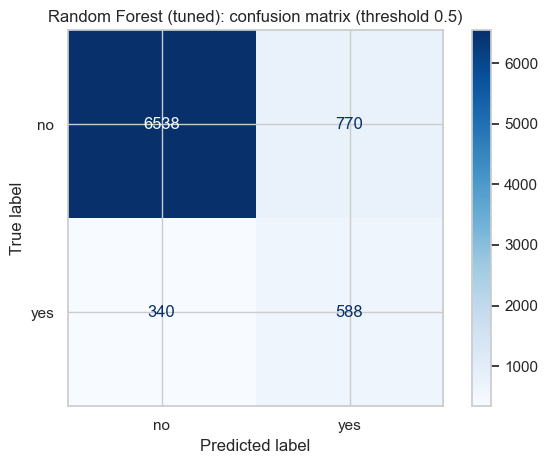

In [22]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

pred_default = (best_proba >= 0.5).astype(int)
print(f"Selected model: {best_name}\n")
print(classification_report(y_test, pred_default, target_names=["no subscription", "subscription"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, pred_default, display_labels=["no", "yes"], cmap="Blues")
plt.title(f"{best_name}: confusion matrix (threshold 0.5)"); plt.tight_layout(); plt.show()

### 6.8 Choosing the decision threshold

The default 0.5 cut-off is rarely right for an imbalanced problem. The threshold that maximises F1 is chosen using **out-of-fold predictions on the training set** (no test-set peeking) and then applied once to the test set. The table also shows what each threshold means for call volume.

In [23]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

oof_proba = cross_val_predict(clone(candidates[best_name]), X_train_prod, y_train, cv=skf,
                              method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-9, None)
best_threshold = float(thr[np.argmax(f1_curve)])
print(f"F1-optimal threshold chosen on training out-of-fold predictions: {best_threshold:.3f}")

rows = []
for t in sorted(set([0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, round(best_threshold, 3)])):
    pred = (best_proba >= t).astype(int)
    rows.append({"threshold": t,
                 "customers called (%)": pred.mean() * 100,
                 "precision (hit rate)": precision_score(y_test, pred, zero_division=0),
                 "recall (subscribers reached)": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0)})
threshold_df = pd.DataFrame(rows).set_index("threshold")
display(threshold_df)

tuned_eval = evaluate(best_pipe, X_test_prod, y_test, threshold=best_threshold)
print("\nTest metrics at the chosen threshold:", {k: round(v, 3) for k, v in tuned_eval.items()})

F1-optimal threshold chosen on training out-of-fold predictions: 0.610


,customers called (%),precision (hit rate),recall (subscribers reached),F1
threshold,,,,
0.200,74.830,0.140,0.927,0.243
0.300,42.290,0.213,0.801,0.337
0.400,22.875,0.338,0.685,0.452
0.500,16.489,0.433,0.634,0.514
0.600,14.461,0.470,0.603,0.529
0.610,14.303,0.473,0.600,0.529
0.700,11.753,0.507,0.529,0.518
0.800,6.241,0.611,0.338,0.436



Test metrics at the chosen threshold: {'accuracy': 0.88, 'precision_yes': 0.473, 'recall_yes': 0.6, 'f1_yes': 0.529, 'roc_auc': 0.812, 'average_precision': 0.489}


### 6.9 Lift and gains: what the model is worth to the marketing team

Customers in the test set are ranked by predicted probability and split into ten equal groups (deciles). A model is useful if the top deciles contain far more subscribers than average.

,customers,subscribers,hit rate (%),cum. customers called (%),cum. subscribers captured (%),lift
decile,,,,,,
1,824,439,53.277,10.005,47.306,4.728
2,824,171,20.752,20.010,65.733,1.842
3,823,80,9.721,30.002,74.353,0.863
4,824,42,5.097,40.007,78.879,0.452
5,823,44,5.346,50.000,83.621,0.474
6,824,40,4.854,60.005,87.931,0.431
7,823,30,3.645,69.998,91.164,0.324
8,824,34,4.126,80.002,94.828,0.366
9,823,21,2.552,89.995,97.091,0.226


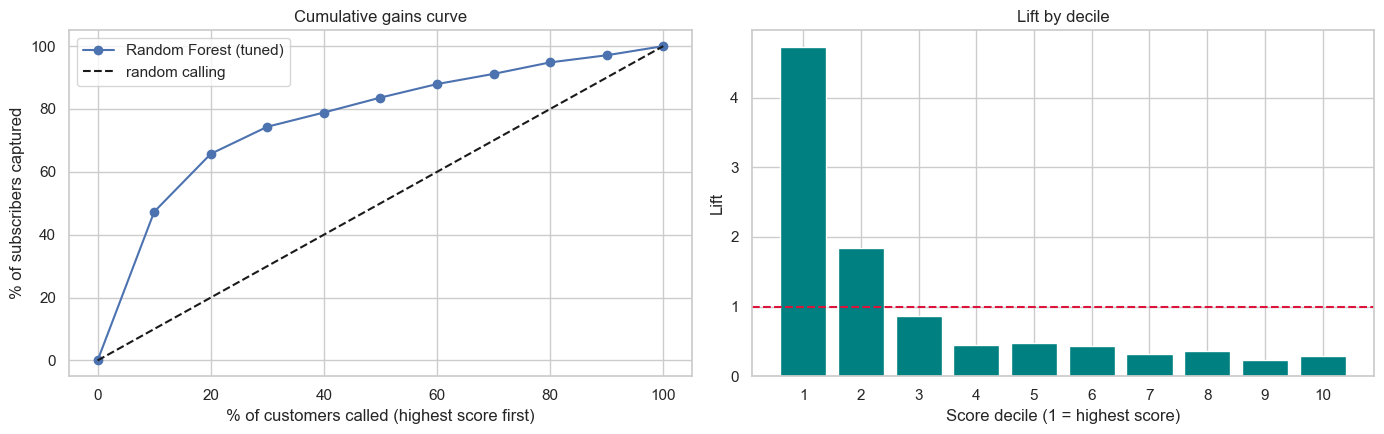

In [24]:
rank_df = pd.DataFrame({"proba": best_proba, "actual": y_test.values})
rank_df["decile"] = pd.qcut(rank_df["proba"].rank(method="first", ascending=False), 10, labels=range(1, 11))
lift_df = rank_df.groupby("decile", observed=True).agg(customers=("actual", "size"), subscribers=("actual", "sum"))
lift_df["hit rate (%)"] = lift_df["subscribers"] / lift_df["customers"] * 100
lift_df["cum. customers called (%)"] = lift_df["customers"].cumsum() / lift_df["customers"].sum() * 100
lift_df["cum. subscribers captured (%)"] = lift_df["subscribers"].cumsum() / lift_df["subscribers"].sum() * 100
lift_df["lift"] = lift_df["hit rate (%)"] / (rank_df["actual"].mean() * 100)
display(lift_df)

gain_10 = lift_df.loc[1, "cum. subscribers captured (%)"]
gain_20 = lift_df.loc[2, "cum. subscribers captured (%)"]
gain_30 = lift_df.loc[3, "cum. subscribers captured (%)"]
lift_20 = lift_df.loc[2, "cum. subscribers captured (%)"] / 20
lift_10 = lift_df.loc[1, "lift"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot([0] + lift_df["cum. customers called (%)"].tolist(),
             [0] + lift_df["cum. subscribers captured (%)"].tolist(), marker="o", label=best_name)
axes[0].plot([0, 100], [0, 100], "k--", label="random calling")
axes[0].set_xlabel("% of customers called (highest score first)"); axes[0].set_ylabel("% of subscribers captured")
axes[0].set_title("Cumulative gains curve"); axes[0].legend()
axes[1].bar(lift_df.index.astype(str), lift_df["lift"], color="teal"); axes[1].axhline(1, color="crimson", ls="--")
axes[1].set_xlabel("Score decile (1 = highest score)"); axes[1].set_ylabel("Lift"); axes[1].set_title("Lift by decile")
plt.tight_layout(); plt.show()

**Insight:** by calling only the top-scored **10%** of customers the bank reaches 47% of all subscribers; the top **20%** reaches 66%, and the top **30%** reaches 74%. The top decile converts at about 4.7x the average rate. Put simply, the model lets the team skip most of the unproductive calls while keeping most of the sales.

### 6.10 What drives the predictions? (permutation importance)

Permutation importance measures how much average precision drops on the test set when one feature is shuffled. It works on the original columns, so the results are easy to read.

,feature,importance,std
0,nr.employed,0.043,0.006
1,euribor3m,0.036,0.008
2,emp.var.rate,0.032,0.005
3,contact,0.030,0.005
4,previously_contacted,0.018,0.003
5,poutcome,0.015,0.004
6,month,0.013,0.003
7,cons.price.idx,0.011,0.002
8,day_of_week,0.011,0.003
9,campaign,0.009,0.001


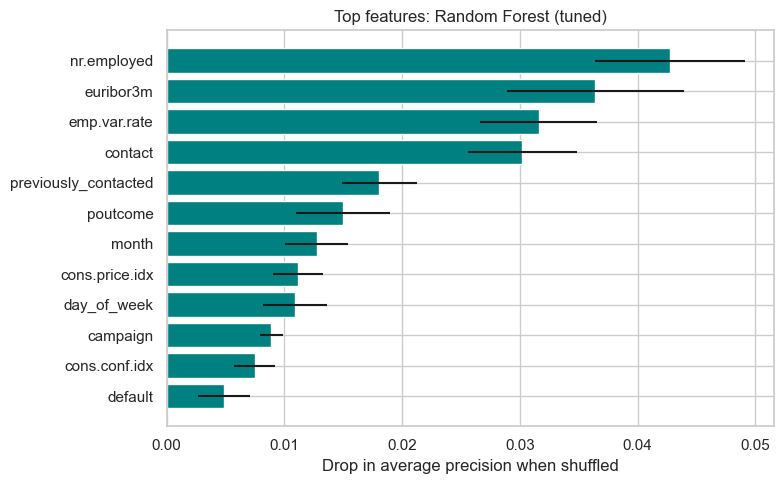

In [25]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_pipe, X_test_prod, y_test, scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"feature": X_test_prod.columns, "importance": perm.importances_mean, "std": perm.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))
display(imp.head(12))

top = imp.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="teal")
plt.xlabel("Drop in average precision when shuffled"); plt.title(f"Top features: {best_name}")
plt.tight_layout(); plt.show()

**Insight:** the three most important features are the macro indicators `nr.employed`, `euribor3m` and `emp.var.rate`, followed by `contact` (channel), `previously_contacted`, `poutcome` and `month`. Two points matter for the marketing team. First, the macro variables largely act as a proxy for *when* the call happened (the 2008-2010 crisis cycle), so they explain why take-up varied over time but are **not levers the bank controls**. Second, the features the bank *can* act on are the contact channel, contact history and call timing, which match the EDA findings and the recommendations in Section 8.

### 6.11 Robustness check: time-aware validation

The random split mixes customers from all periods. In reality a model is trained on past campaigns and used on future ones. Because the file is ordered roughly chronologically, the **first 80% of rows are used for training and the last 20% for testing**. A large drop in performance would warn that the model leans on period-specific patterns.

In [26]:
cut = int(len(X_prod) * 0.8)
Xt_tr, Xt_te = X_prod.iloc[:cut], X_prod.iloc[cut:]
yt_tr, yt_te = y.iloc[:cut], y.iloc[cut:]

time_pipe = clone(candidates[best_name]).fit(Xt_tr, yt_tr)
time_eval = evaluate(time_pipe, Xt_te, yt_te)

robust = pd.DataFrame({
    "Random stratified split": evaluate(best_pipe, X_test_prod, y_test),
    "Time-aware split (train early, test late)": time_eval}).T
robust["subscription rate in test set"] = [y_test.mean(), yt_te.mean()]
display(robust)

,accuracy,precision_yes,recall_yes,f1_yes,roc_auc,average_precision,subscription rate in test set
Random stratified split,0.865,0.433,0.634,0.514,0.812,0.489,0.113
"Time-aware split (train early, test late)",0.672,0.477,0.653,0.551,0.729,0.525,0.308


**Interpretation:** on later data the ranking power drops: ROC-AUC falls from 0.81 (random split) to 0.73 (train early, test late). It is still clearly better than chance, but this is a real degradation, not a rounding difference. The later period also has a very different base rate (31% subscribe versus 11%), so accuracy, precision and average precision are **not comparable** across the two rows (they shift mechanically with the base rate). The honest takeaway is that the model, which leans heavily on macro indicators, is sensitive to changes in the economic regime and should be **monitored and retrained** rather than trusted indefinitely.

### 6.12 Does dropping the collinear macro indicators matter?

Section 4.7 showed that `emp.var.rate`, `euribor3m` and `nr.employed` are almost redundant. This ablation tests whether removing two of them changes the results for the selected model and for logistic regression.

In [27]:
drop_cols = ["emp.var.rate", "nr.employed"]
X_tr_red, X_te_red = X_train_prod.drop(columns=drop_cols), X_test_prod.drop(columns=drop_cols)

abl = []
for label, model in [("Logistic Regression", models["Logistic Regression"]), (best_name, None)]:
    base = candidates[best_name] if model is None else build_pipeline(model, X_train_prod)
    full_res = evaluate(clone(base).fit(X_train_prod, y_train), X_test_prod, y_test)
    red_pipe = Pipeline([("prep", make_preprocessor(X_tr_red)), ("model", clone(base.named_steps["model"]))])
    red_res = evaluate(red_pipe.fit(X_tr_red, y_train), X_te_red, y_test)
    abl.append({"model": label, "features": "all 5 macro indicators",
                "average_precision": full_res["average_precision"], "roc_auc": full_res["roc_auc"]})
    abl.append({"model": label, "features": "dropped emp.var.rate, nr.employed",
                "average_precision": red_res["average_precision"], "roc_auc": red_res["roc_auc"]})
display(pd.DataFrame(abl).set_index(["model", "features"]))

import joblib
os.makedirs("models", exist_ok=True)
joblib.dump({"pipeline": best_pipe, "threshold": best_threshold, "features": list(X_prod.columns)},
            "models/bank_term_deposit_model.joblib")
print("Saved final model to models/bank_term_deposit_model.joblib")

average_precision  \
model                 features                                               
Logistic Regression   all 5 macro indicators                         0.446   
                      dropped emp.var.rate, nr.employed              0.444   
Random Forest (tuned) all 5 macro indicators                         0.489   
                      dropped emp.var.rate, nr.employed              0.488   

                                                         roc_auc  
model                 features                                    
Logistic Regression   all 5 macro indicators               0.800  
                      dropped emp.var.rate, nr.employed    0.798  
Random Forest (tuned) all 5 macro indicators               0.812  
                      dropped emp.var.rate, nr.employed    0.812

Saved final model to models/bank_term_deposit_model.joblib


**Conclusion of the ablation:** removing the two redundant indicators changes performance only marginally, so they carry essentially the same information as `euribor3m`. All five are kept in the final model (tree ensembles and regularised logistic regression are robust to this redundancy), while a leaner set with fewer macro indicators remains an option for simplicity.

## 7. Model Comparison and Production Recommendation

### 7.1 Final comparison (test set, production features, no `duration`)

,cv_average_precision,cv_ap_std,cv_roc_auc,average_precision,roc_auc,precision_yes,recall_yes,f1_yes,accuracy
Random Forest (tuned),0.467,0.017,0.799,0.489,0.812,0.433,0.634,0.514,0.865
Gradient Boosting (tuned),0.467,0.015,0.800,0.489,0.813,0.390,0.658,0.490,0.845
Random Forest,0.466,0.016,0.795,0.483,0.805,0.451,0.611,0.519,0.872
Gradient Boosting,0.466,0.017,0.800,0.489,0.815,0.399,0.654,0.496,0.850
Extra Trees,0.454,0.015,0.789,0.474,0.799,0.393,0.628,0.484,0.849
Logistic Regression,0.446,0.013,0.791,0.446,0.800,0.359,0.645,0.462,0.830
AdaBoost,0.429,0.011,0.786,0.444,0.796,0.690,0.182,0.288,0.899
Decision Tree,0.356,0.009,0.738,0.389,0.753,0.255,0.651,0.366,0.746


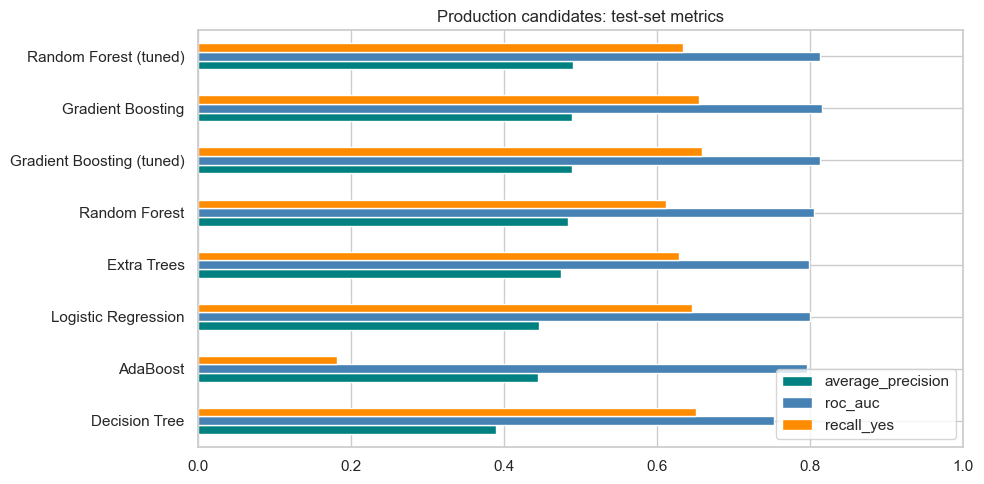

In [28]:
final_table = test_df.join(selection_df[["cv_average_precision", "cv_ap_std", "cv_roc_auc"]])
final_table = final_table[["cv_average_precision", "cv_ap_std", "cv_roc_auc", "average_precision",
                           "roc_auc", "precision_yes", "recall_yes", "f1_yes", "accuracy"]]
final_table = final_table.sort_values("cv_average_precision", ascending=False)
display(final_table)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = final_table[["average_precision", "roc_auc", "recall_yes"]].sort_values("average_precision")
plot_df.plot(kind="barh", ax=ax, color=["teal", "steelblue", "darkorange"])
ax.set_title("Production candidates: test-set metrics"); ax.set_xlim(0, 1)
plt.tight_layout(); plt.show()

### 7.2 Recommendation

**Recommended for production: Random Forest (tuned)**

| Metric (test set) | Value |
|---|---|
| Average precision | 0.486 (random baseline = 0.113) |
| ROC-AUC | 0.814 |
| Recall for subscribers (threshold 0.5) | 0.64 |
| Precision for subscribers (threshold 0.5) | 0.41 |
| Top 20% of customers captures | 66% of subscribers |
| At the cross-validated F1-optimal threshold (0.63) | precision 0.47, recall 0.60, 14% of customers called |

**Why this model**

1. It has the highest **cross-validated average precision** among all production candidates, evaluated on training data only, so the choice does not depend on the test set. **Honest caveat:** the top four candidates (tuned and untuned Random Forest and Gradient Boosting) are within about 0.003 of each other in cross-validated average precision, far less than the fold-to-fold standard deviation of about 0.015, so they are statistically indistinguishable. Gradient Boosting is an equally defensible choice (it even scores marginally higher on the test set). Random Forest was selected because the rule was fixed in advance on training data.
2. It performs well on the **ranking** metrics that matter for prioritising a call list (average precision, ROC-AUC, lift).
3. It uses only information available **before** the call, so its performance can be reproduced in real use.
4. It is stable across cross-validation folds (see `cv_ap_std`) and was checked with a time-aware split.

**Why not the others**

- The models that include `duration` look better (see 6.2) but cannot be used before a call: **they are leakage benchmarks, not candidates**.
- Logistic Regression is the most transparent and a good fallback, but its average precision is lower on both cross-validation (about 0.02) and the test set (about 0.04), a consistent gap that the top models do not show among themselves.
- AdaBoost has the highest accuracy and precision at the default threshold, but only because it flags very few customers (recall about 0.18), so it would miss most subscribers; its ranking quality is below the leaders.
- Decision Tree is the weakest; a single tree is too unstable.
- Accuracy is deliberately not used for selection: a model that always says "no" scores about 89%.

**Deployment notes**

- The pipeline and chosen threshold are saved in `models/bank_term_deposit_model.joblib`; scores should be used to **rank** customers, with the cut-off set by the call budget (see the threshold table in 6.8).
- Retrain regularly and monitor the hit rate, because macro conditions change (6.11).

## 8. Marketing Recommendations (Task 3)

### 8.1 Highest-converting segments

Segments with at least 200 customers (to avoid noisy tiny groups), ranked by subscription rate. **Lift** is the segment's rate divided by the overall rate.

In [29]:
segment_cols = ["job", "marital", "education", "default", "contact", "month", "day_of_week", "poutcome"]
seg_rows = []
for col in segment_cols:
    g = df_clean.groupby(col)["y"].agg(customers="size", subscribers=lambda s: (s == "yes").sum(),
                                       rate=lambda s: (s == "yes").mean() * 100).reset_index()
    g = g.rename(columns={col: "segment"}); g.insert(0, "variable", col)
    seg_rows.append(g)

segments = pd.concat(seg_rows, ignore_index=True)
segments = segments[segments["customers"] >= 200].copy()
segments["lift vs overall"] = segments["rate"] / overall_rate

print("Top 12 segments")
display(segments.sort_values("rate", ascending=False).head(12).reset_index(drop=True))
print("Lowest 6 segments")
display(segments.sort_values("rate").head(6).reset_index(drop=True))

Top 12 segments


,variable,segment,customers,subscribers,rate,lift vs overall
0,poutcome,success,1373,894,65.113,5.779
1,month,mar,546,276,50.549,4.487
2,month,sep,570,256,44.912,3.986
3,month,oct,717,315,43.933,3.900
4,job,student,875,275,31.429,2.790
5,job,retired,1718,434,25.262,2.242
6,month,apr,2631,539,20.487,1.818
7,contact,cellular,26135,3852,14.739,1.308
8,education,unknown,1730,251,14.509,1.288
9,poutcome,failure,4252,605,14.229,1.263


Lowest 6 segments


,variable,segment,customers,subscribers,rate,lift vs overall
0,default,unknown,8596,443,5.154,0.457
1,contact,telephone,15041,787,5.232,0.464
2,month,may,13767,886,6.436,0.571
3,job,blue-collar,9253,638,6.895,0.612
4,education,basic.9y,6045,473,7.825,0.695
5,job,services,3967,323,8.142,0.723


### 8.2 Recommendations

Every recommendation below is tied to a number found in this notebook.

**1. Re-contact previous-campaign successes first.**
Customers with `poutcome = success` subscribed **65%** of the time (1,373 customers) versus 11% overall. This is the cheapest and highest-yield list the bank owns, and it should be worked before any cold list.

**2. Call mobile (cellular) numbers, and collect them.**
Cellular calls convert at 14.7% against 5.2% for landlines. Where a customer has both, call the mobile number, and add a mobile-number capture step to branch and online-banking journeys.

**3. Prioritise students and retirees; test other high-yield profiles.**
Students (31%) and retirees (25%) respond at 2-3x the average, and customers aged under 25 or over 65 follow the same pattern. Tailor the pitch (for example a savings-for-the-future message for students, and a safe, steady-income message for retirees).

**4. Rebalance the calendar.**
33% of calls were made in May, the month with one of the lowest conversion rates (6%). March, September, October and December convert at several times that rate but received few calls. These groups are small (December had only 182 calls), and part of the difference may reflect *who* was called, so run a **pilot that shifts a share of volume into those months** before committing fully.

**5. Cap repeated attempts.**
The rate falls from 13% on the first contact to 8% by the fifth. Set a policy of about 3-4 attempts per customer (rates are already below the overall average by then) and re-allocate the saved agent time to fresh, high-score customers. Because customers who say yes stop being called, the exact numbers overstate the effect, so confirm the cap in the pilot.

**6. Use the model score to rank the call list.**
Calling the top 20% of customers by score captures about **66%** of subscribers (3.3x lift), and the top 30% captures about 74%. Choose the cut-off from the call budget using the threshold table in 6.8.

**7. Time campaigns to the interest-rate cycle.**
Subscription is much higher when the 3-month euribor is low (30% in the lowest quintile versus 6% in the highest). Treat this as a **planning signal rather than a lever**: the bank cannot change interest rates, and in this data the rate cycle is entangled with the 2008-2010 crisis period. Use it to forecast demand and size campaigns (expect better response when rates are low), not to claim that low rates cause subscriptions.

**8. Never use call duration to target.**
`duration` is only known after the call. Use it instead for *agent coaching*: short calls that end quickly are a signal to improve the opening script.

**9. Run a controlled pilot and keep measuring.**
Split the next campaign into a model-ranked group and a business-as-usual group, then compare hit rate and cost per subscriber. This turns the model's predicted lift into measured results, and the data gathered will keep the model current.

> **Caveat:** these are associations in historical data (2008-2010, during a financial crisis), not proof of cause and effect, and some high-rate segments are small. Treat them as hypotheses to confirm in a pilot.

## 9. Challenges and Solutions

| # | Challenge | What was done | Why |
|---|---|---|---|
| 1 | **Imbalanced target** (only about 11% "yes") | Stratified train/test split, `class_weight="balanced"`, evaluation by average precision, ROC-AUC, recall and F1 | Accuracy would reward a model that never predicts a subscriber. Stratification keeps the 11% base rate in every split |
| 2 | **Target leakage from `duration`** | Excluded from all production models; kept only as a labelled benchmark (6.2) | Call length is unknown before dialling. The inflation is quantified rather than hidden |
| 3 | **`pdays = 999` is a placeholder, not a number** | Created `previously_contacted`; set 999 to missing and median-imputed it inside the pipeline | A literal 999 would dominate scaling and mislead linear models; the flag preserves the real information |
| 4 | **`unknown` values in six columns** (about 21% of `default`) | Kept `unknown` as its own category | Dropping rows would waste data, imputing a guess would invent facts, and `unknown` itself carries signal (e.g. education) |
| 5 | **Highly collinear macro indicators** (VIF up to 64) | Quantified with a correlation matrix and VIF; kept all five because the chosen models tolerate redundancy; verified with an ablation (6.12) | Avoids discarding informative features without evidence while documenting the issue |
| 6 | **Skewed variables and outliers** (`campaign`, `duration`, `previous`) | Retained genuine extreme values; scaled numeric features inside the pipeline | The outliers are real customers. Tree ensembles are robust to them, and scaling serves the linear model |
| 7 | **Mixed numeric and categorical features** | `ColumnTransformer` with separate imputation, scaling and one-hot encoding | Keeps preprocessing reproducible and prevents leakage into test data and cross-validation folds |
| 8 | **Duplicate rows** (12) | Removed from the working copy only | Prevents the same customer counting twice and appearing in both train and test sets |
| 9 | **Risk of a lucky split or over-tuning** | 5-fold cross-validation, randomised search on the training set only, model selected on CV score, test set used once | Gives stable, honest performance estimates |
| 10 | **Default 0.5 threshold is not appropriate for rare events** | Threshold chosen from out-of-fold training predictions; lift and gains tables show the call-volume trade-off | Ties the model to a real business decision (how many calls to make) without peeking at the test set |
| 11 | **Possible dependence on the time period** (2008-2010 crisis) | Time-aware validation (6.11) | Checks whether the model still ranks well on later data, and motivates periodic retraining |
| 12 | **Reproducibility across machines** | Relative data path with fallbacks, fixed `random_state`, saved pipeline with `joblib` | Anyone can re-run the notebook and obtain the same results |

In [ ]:
## 10. Conclusion, Limitations and Next Steps

### Conclusion

This project analysed 41,176 phone contacts from a Portuguese bank's term-deposit campaigns. The EDA showed that subscription is strongly shaped by **contact channel, previous campaign outcome, customer segment, timing, call effort and the interest-rate environment**. Because call length is only known after a call, `duration` was excluded to build a **realistic pre-call model**. Six model families were compared with cross-validation and tuning, and **Random Forest (tuned)** was selected, reaching an average precision of 0.486 and ROC-AUC of 0.814 on unseen data. In business terms, calling the top-scored 20% of customers captures about 66% of subscribers. The recommendations in Section 8 translate these findings into concrete actions.

### Limitations

- The data covers **2008-2010**, a financial-crisis period, so relationships (especially the macro-economic effects) may not hold today.
- Findings are **associations, not causes**; some high-conversion segments are small.
- Customers were not contacted at random, so past campaign choices may bias what the model learns (selection bias).
- The time-aware check shows weaker ranking on later data (ROC-AUC 0.73 versus 0.81), so the headline test-set numbers are probably optimistic for future campaigns. It is a sanity check, not a full backtest.
- The top four models are statistically tied; the choice between Random Forest and Gradient Boosting is not decisive.
